# 03 · Grover's search (3 qubits)

**The problem.** Among $N = 2^n$ items, one is "marked", and you can only recognise it with an oracle.
Classically you need about $N/2$ checks on average. Grover needs about $\frac{\pi}{4}\sqrt{N}$, a **quadratic** speed-up.

**How it works:** start in the uniform superposition $|s\rangle$, then repeat two reflections:
1. **Oracle**: flip the *sign* of the marked state's amplitude, $|w\rangle \to -|w\rangle$.
2. **Diffuser** $2|s\rangle\langle s| - I$: reflect every amplitude about the *average* amplitude
   ("inversion about the mean"). The marked amplitude is now negative and far below the mean,
   so it gets reflected to well above it.

Each round rotates the state by an angle $2\theta$ towards $|w\rangle$, where $\sin\theta = 1/\sqrt{N}$.
After $k$ rounds $P(\text{success}) = \sin^2((2k+1)\theta)$. If you do **too many** rounds it rotates *past* the target.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector
from qiskit.visualization import plot_histogram
from qiskit_aer import AerSimulator

sim = AerSimulator()
SHOTS = 4096
COLORS = ["#2a78d6", "#eb6834", "#1baf7a"]  # fixed series order: blue, orange, aqua

n = 3
target = "101"   # the marked item, in Qiskit order (q2 q1 q0)
N = 2 ** n

### Oracle: phase-flip only $|101\rangle$
A multi-controlled Z (CCZ) flips the sign of $|111\rangle$ and nothing else. To flip a different
state instead, put `X` gates on the qubits that should be 0 in the target. That maps the target onto
$|111\rangle$, then we apply CCZ and undo the `X`s.

In [2]:
def mcz(qc, qubits):
    """Multi-controlled Z = H . MCX . H on the last qubit: phase -1 on |11...1> only."""
    *controls, tgt = qubits
    qc.h(tgt)
    qc.mcx(controls, tgt)   # Toffoli-like: flip tgt iff all controls are 1
    qc.h(tgt)

def phase_oracle(target):
    n = len(target)
    qc = QuantumCircuit(n, name="Oracle")
    # reversed(): target[-1] is qubit 0 because Qiskit strings are little-endian
    zeros = [q for q, bit in enumerate(reversed(target)) if bit == "0"]
    if zeros:
        qc.x(zeros)          # map |target> -> |11...1>
    mcz(qc, list(range(n)))  # sign-flip |11...1>
    if zeros:
        qc.x(zeros)          # map back
    return qc

def diffuser(n):
    """Inversion about the mean, 2|s><s| - I (up to a global phase)."""
    qc = QuantumCircuit(n, name="Diffuser")
    qc.h(range(n))           # |s> -> |00..0>
    qc.x(range(n))           # |00..0> -> |11..1>
    mcz(qc, list(range(n)))  # sign-flip |11..1>, i.e. reflect about |00..0>
    qc.x(range(n))           # undo
    qc.h(range(n))           # undo -> reflection is now about |s>
    return qc

Check the oracle on its own: after the uniform superposition, **only** the amplitude of `101` should be negative.

In [3]:
qc = QuantumCircuit(n)
qc.h(range(n))
qc.compose(phase_oracle(target), inplace=True)
amps = Statevector.from_instruction(qc).data
for i, a in enumerate(amps):
    label = format(i, f"0{n}b")
    print(label, f"{a.real:+.3f}", "<- marked" if label == target else "")

000 +0.354 
001 +0.354 
010 +0.354 
011 +0.354 
100 +0.354 
101 -0.354 <- marked
110 +0.354 
111 +0.354 


optimal iterations: 2


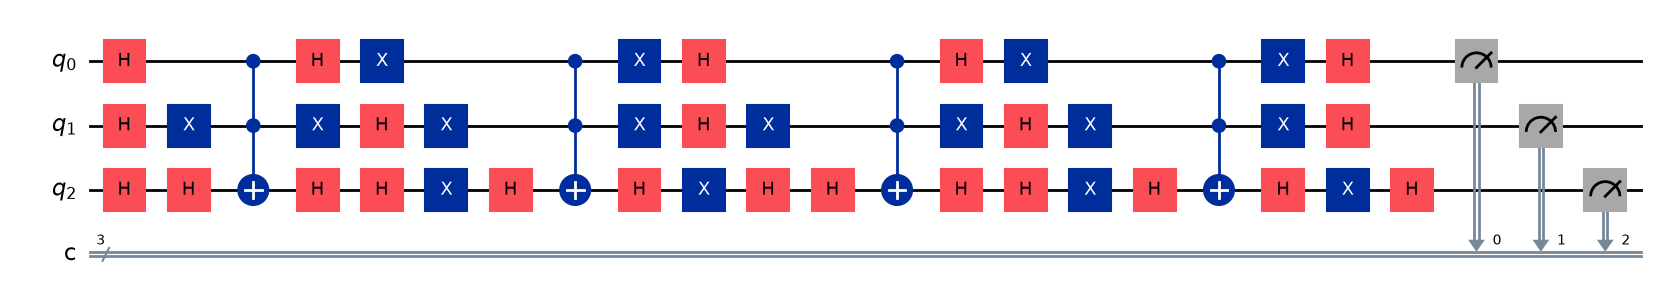

In [4]:
def grover(target, iterations):
    n = len(target)
    qc = QuantumCircuit(n, n)
    qc.h(range(n))                      # start in |s>: every item has amplitude 1/sqrt(N)
    for _ in range(iterations):
        qc.compose(phase_oracle(target), inplace=True)   # mark
        qc.compose(diffuser(n), inplace=True)            # amplify
    qc.measure(range(n), range(n))
    return qc

k_opt = int(np.floor(np.pi / 4 * np.sqrt(N)))   # = 2 for N = 8
print("optimal iterations:", k_opt)
grover(target, k_opt).draw("mpl", fold=-1)

P(101) measured = 0.944   theory = 0.945


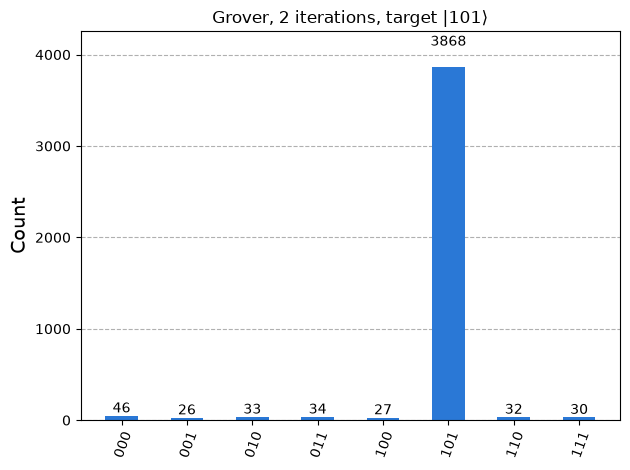

In [5]:
counts = sim.run(transpile(grover(target, k_opt), sim), shots=SHOTS).result().get_counts()
theta = np.arcsin(1 / np.sqrt(N))
print(f"P({target}) measured = {counts.get(target, 0) / SHOTS:.3f}   theory = {np.sin((2 * k_opt + 1) * theta) ** 2:.3f}")
plot_histogram(counts, color=COLORS[0], title=f"Grover, {k_opt} iterations, target |{target}⟩")

### Too many iterations overshoots
Sweep the number of iterations and compare with $\sin^2((2k+1)\theta)$:

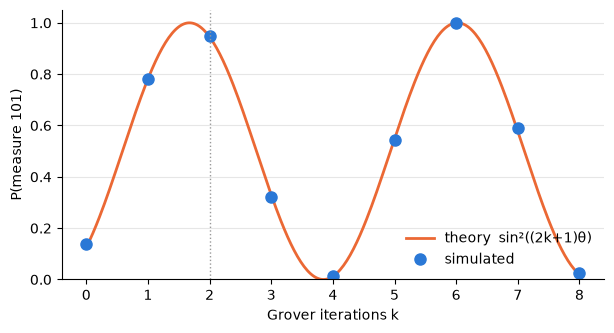

In [6]:
ks = np.arange(0, 9)
measured = []
for k in ks:
    c = sim.run(transpile(grover(target, k), sim), shots=SHOTS).result().get_counts()
    measured.append(c.get(target, 0) / SHOTS)

k_fine = np.linspace(0, ks[-1], 300)
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(k_fine, np.sin((2 * k_fine + 1) * theta) ** 2, color=COLORS[1], lw=2, label="theory  sin²((2k+1)θ)")
ax.plot(ks, measured, "o", color=COLORS[0], ms=8, label="simulated")
ax.axvline(k_opt, color="0.6", lw=1, ls=":")
ax.set(xlabel="Grover iterations k", ylabel=f"P(measure {target})", ylim=(0, 1.05))
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="0.9")
ax.legend(frameon=False, loc="lower right")
plt.show()

**Try it:** change `target`, or set `n = 4` (16 items, `k_opt = 3`). The success probability peaks,
falls back almost to zero, then rises again. Grover's algorithm is a rotation, not a search that keeps improving.